# 03 — Feature Engineering Template

Plantilla reutilizable para **diagnosticar, crear y evaluar features** en problemas de clasificación y regresión.

La notebook separa tres etapas:
1. **Diagnóstico:** identifica oportunidades de transformación usando únicamente el conjunto de entrenamiento.
2. **Experimentación:** permite activar transformaciones generales y definir features derivadas específicas del dominio.
3. **Evaluación:** compara un modelo con features base contra el mismo modelo con features engineered, utilizando validation para seleccionar y reservando test para una evaluación final.

> Las transformaciones no se aplican automáticamente por detectar una asimetría o una correlación. La notebook propone oportunidades; vos decidís qué probar. No modifica el dataset original.

## Workflow recomendado

```text
Dataset
  │
  ├── Train ── Diagnóstico ── Feature Engineering ── Comparación en Validation
  │                                                    │
  ├── Validation ──────────────────────────────────────┘
  │                                                    │
  └── Test (reservado) <── Reentrenar variante ganadora ┘
```

- **Baseline features:** preparación mínima, incluyendo extracción estándar de componentes de fecha.
- **Engineered features:** baseline + transformaciones y features derivadas configuradas.
- Los imputadores y encoders se ajustan dentro del pipeline, solamente con train.
- Frequency encoding aprende sus frecuencias en train. Target encoding, cuando está disponible, utiliza el `TargetEncoder` de scikit-learn con cross-fitting.
- Las features se seleccionan mirando validation; test se usa una sola vez al final.

Para datos temporales, elegí `SPLIT_STRATEGY = "time"` y configurá `TIME_COLUMN`. Para datos agrupados (por ejemplo, varios registros del mismo cliente), adaptá el split a un GroupShuffleSplit/GroupKFold para evitar que un mismo grupo aparezca en más de una partición.

## 1. Configuración

In [1]:
from pathlib import Path

# Dataset y variable objetivo
DATA_PATH = Path("Dataset/Telco/Telco-Customer-Churn.csv")
TARGET = "Churn"                 # Nombre de la variable objetivo
SEPARATOR = ","
READ_CSV_KWARGS = {}               # Ejemplo: {"encoding": "utf-8"}

# Tipo de problema: "auto", "classification" o "regression"
PROBLEM_TYPE = "auto"

# Columnas que no deben utilizarse como predictoras
DROP_COLUMNS = []                  # Ejemplo: ["post_event_status"]
ID_COLUMNS = []                    # Ejemplo: ["customer_id"]

# Overrides de tipos de datos
DATETIME_COLUMNS = []              # Fechas almacenadas como texto
FORCE_NUMERIC_COLUMNS = []         # Números almacenados como texto
FORCE_CATEGORICAL_COLUMNS = []     # Códigos numéricos que representan categorías
AUTO_DETECT_DATETIME = True
AUTO_DATETIME_MIN_PARSE_RATIO = 0.85

# División de datos
SPLIT_STRATEGY = "random"          # "random" o "time"
TIME_COLUMN = None                 # Obligatoria si SPLIT_STRATEGY = "time"
TEST_SIZE = 0.20                   # Fracción total reservada para test
VALIDATION_SIZE = 0.20             # Fracción del bloque development reservada para validation
RANDOM_STATE = 42

# Diagnóstico
SKEW_THRESHOLD = 1.0
HIGH_CARDINALITY_THRESHOLD = 20
HIGH_CORRELATION_THRESHOLD = 0.90
TOP_DIAGNOSTIC_FEATURES = 30

# Encoding de variables categóricas de alta cardinalidad
HIGH_CARDINALITY_ENCODING = "frequency"  # "frequency", "target" o "onehot"
OHE_MAX_CATEGORIES = 30
OHE_MIN_FREQUENCY = None             # Ejemplo: 0.01 o 5; None para desactivar
SCALE_NUMERIC = False                # En árboles normalmente no es necesario

# Modelo utilizado para comparar features
MODEL_NAME = "random_forest"         # "random_forest" o "xgboost" (si está instalado)
N_ESTIMATORS = 300
MAX_DEPTH = None
MODEL_N_JOBS = -1

# Métrica para elegir la variante en validation
# Clasificación: "f1_weighted" o "roc_auc" (cuando corresponda)
# Regresión: "rmse", "mae" o "logrmse"
SELECTION_METRIC_CLASSIFICATION = "f1_weighted"
SELECTION_METRIC_REGRESSION = "rmse"

# Exportación opcional de las matrices de features engineered (sin imputar ni encodear)
SAVE_ENGINEERED_DATA = False
ENGINEERED_DATA_PATH = Path("engineered_features.csv")

print("Configuración cargada.")

Configuración cargada.


## 2. Imports y configuración visual

In [2]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from pandas.api.types import (
    is_bool_dtype, is_datetime64_any_dtype, is_numeric_dtype,
    is_object_dtype, is_string_dtype
)
from scipy.stats import skew

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score, average_precision_score, f1_score,
    mean_absolute_error, mean_squared_error, r2_score,
    precision_score, recall_score, roc_auc_score
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.utils.multiclass import type_of_target

try:
    from sklearn.preprocessing import TargetEncoder
    TARGET_ENCODER_AVAILABLE = True
except ImportError:
    TARGET_ENCODER_AVAILABLE = False
    print("TargetEncoder no disponible en esta versión de scikit-learn; se usará frequency encoding si se solicita target encoding.")

try:
    from xgboost import XGBClassifier, XGBRegressor
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False
    print("XGBoost no está instalado. Podés usar MODEL_NAME='random_forest'.")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print(f"Pandas: {pd.__version__} | NumPy: {np.__version__}")
print(f"TargetEncoder: {TARGET_ENCODER_AVAILABLE} | XGBoost: {XGBOOST_AVAILABLE}")

Pandas: 2.2.3 | NumPy: 2.2.4
TargetEncoder: True | XGBoost: True


## 3. Carga y validaciones iniciales

In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo: {DATA_PATH.resolve()}\n"
        "Actualizá DATA_PATH en la sección de configuración."
    )

if TARGET is None:
    raise ValueError("Definí TARGET en la sección de configuración.")

# Para otros formatos, reemplazar esta línea por el lector correspondiente.
df = pd.read_csv(DATA_PATH, sep=SEPARATOR, **READ_CSV_KWARGS)

if df.empty:
    raise ValueError("El dataset está vacío.")
if TARGET not in df.columns:
    raise KeyError(f"La columna TARGET='{TARGET}' no existe en el dataset.")

print(f"Dataset: {DATA_PATH}")
print(f"Dimensiones: {df.shape[0]:,} filas × {df.shape[1]:,} columnas")
display(df.head())

Dataset: Dataset/Telco/Telco-Customer-Churn.csv
Dimensiones: 7,043 filas × 21 columnas


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
columns_to_drop = ['customerID'] #Agregar columnas a dropear segun el caso
df = df.drop(columns=columns_to_drop)


## 4. Preparación inicial y detección de tipos

Se trabaja sobre copias. Se eliminan solamente filas sin target, porque no pueden utilizarse para entrenamiento supervisado. No se imputan features ni se aprende ningún encoding en esta sección.

La detección automática de fechas es heurística. Revisá `detected_datetime_columns` y agregá o quitá columnas en `DATETIME_COLUMNS` si la inferencia no coincide con el significado real de los datos.

In [5]:
def infer_problem_type(y, configured_type="auto"):
    configured_type = configured_type.lower()
    if configured_type in {"classification", "regression"}:
        return configured_type
    if configured_type != "auto":
        raise ValueError("PROBLEM_TYPE debe ser 'auto', 'classification' o 'regression'.")

    unique_count = y.nunique(dropna=True)
    unique_ratio = unique_count / max(len(y), 1)
    numeric_target = is_numeric_dtype(y) and not is_bool_dtype(y)

    if (not numeric_target) or (unique_count <= 20 and unique_ratio <= 0.05):
        return "classification"
    return "regression"


def parse_datetime_series(series):
    """Parse dates robustly without changing the original series."""
    try:
        return pd.to_datetime(series, errors="coerce", format="mixed")
    except (TypeError, ValueError):
        return pd.to_datetime(series, errors="coerce")


work_df = df.copy()
rows_before = len(work_df)
work_df = work_df.dropna(subset=[TARGET]).copy()
print(f"Filas sin target descartadas: {rows_before - len(work_df):,}")

# Explicit type overrides
for col in FORCE_NUMERIC_COLUMNS:
    if col in work_df.columns and col != TARGET:
        work_df[col] = pd.to_numeric(work_df[col], errors="coerce")

for col in FORCE_CATEGORICAL_COLUMNS:
    if col in work_df.columns and col != TARGET:
        work_df[col] = work_df[col].astype("string")

# Detect datetime columns from dtypes, explicit config and conservative string heuristics
excluded_for_features = set([TARGET] + DROP_COLUMNS + ID_COLUMNS)
detected_datetime_columns = [
    col for col in work_df.columns
    if col not in excluded_for_features and is_datetime64_any_dtype(work_df[col])
]

for col in DATETIME_COLUMNS:
    if col in work_df.columns and col not in excluded_for_features:
        detected_datetime_columns.append(col)

if AUTO_DETECT_DATETIME:
    for col in work_df.columns:
        if col in excluded_for_features or col in detected_datetime_columns:
            continue
        series = work_df[col]
        if not (is_object_dtype(series) or is_string_dtype(series)):
            continue
        non_missing = series.dropna().astype(str)
        if len(non_missing) < 3:
            continue
        # Require date-like separators to reduce false positives (e.g. ordinary text categories).
        date_like_ratio = non_missing.str.contains(r"[-/:T]", regex=True).mean()
        if date_like_ratio < 0.60:
            continue
        parsed = parse_datetime_series(series)
        parse_ratio = parsed.notna().sum() / max(series.notna().sum(), 1)
        if parse_ratio >= AUTO_DATETIME_MIN_PARSE_RATIO:
            detected_datetime_columns.append(col)

# Deduplicate, convert and report
detected_datetime_columns = list(dict.fromkeys(detected_datetime_columns))
for col in detected_datetime_columns:
    work_df[col] = parse_datetime_series(work_df[col])

problem_type = infer_problem_type(work_df[TARGET], PROBLEM_TYPE)
print(f"Tipo de problema: {problem_type.upper()}")
print("Fechas detectadas:", detected_datetime_columns if detected_datetime_columns else "Ninguna")

if problem_type == "classification":
    label_encoder = LabelEncoder()
    y_all = pd.Series(
        label_encoder.fit_transform(work_df[TARGET].astype(str)),
        index=work_df.index,
        name=TARGET
    )
    print("Clases:", list(label_encoder.classes_))
else:
    y_all = pd.to_numeric(work_df[TARGET], errors="coerce")
    valid_target = y_all.notna()
    dropped = int((~valid_target).sum())
    if dropped:
        print(f"Filas con target no numérico descartadas: {dropped:,}")
    work_df = work_df.loc[valid_target].copy()
    y_all = y_all.loc[valid_target].astype(float).rename(TARGET)

feature_columns = [
    col for col in work_df.columns
    if col not in excluded_for_features
]
if not feature_columns:
    raise ValueError("No quedaron features. Revisá TARGET, DROP_COLUMNS e ID_COLUMNS.")

X_all = work_df[feature_columns].copy()

# Keep configured/detected datetime fields as datetime for subsequent feature extraction.
print(f"Features iniciales: {X_all.shape[1]}")
display(pd.DataFrame({
    "feature": X_all.columns,
    "dtype": [str(X_all[col].dtype) for col in X_all.columns],
    "missing_%": [X_all[col].isna().mean() * 100 for col in X_all.columns],
    "unique": [X_all[col].nunique(dropna=True) for col in X_all.columns]
}))

Filas sin target descartadas: 0
Tipo de problema: CLASSIFICATION
Fechas detectadas: Ninguna
Clases: ['No', 'Yes']
Features iniciales: 19


,feature,dtype,missing_%,unique
0,gender,object,0.0,2
1,SeniorCitizen,int64,0.0,2
2,Partner,object,0.0,2
3,Dependents,object,0.0,2
4,tenure,int64,0.0,73
5,PhoneService,object,0.0,2
6,MultipleLines,object,0.0,3
7,InternetService,object,0.0,3
8,OnlineSecurity,object,0.0,3
9,OnlineBackup,object,0.0,3


## 5. Train / validation / test split

Validation se utiliza para comparar las variantes de features. Test queda reservado para una única evaluación de la variante seleccionada.

- `SPLIT_STRATEGY = "random"`: split aleatorio; clasificación intenta mantener la proporción de clases.
- `SPLIT_STRATEGY = "time"`: ordena cronológicamente y reserva los registros más recientes para validation y test. Requiere `TIME_COLUMN`.

In [6]:
def safe_stratify(y_values):
    if problem_type != "classification":
        return None
    counts = pd.Series(y_values).value_counts()
    if len(counts) < 2 or counts.min() < 2:
        print("Warning: no se puede estratificar de forma segura; se utilizará split aleatorio sin stratify.")
        return None
    return y_values


if not (0 < TEST_SIZE < 1 and 0 < VALIDATION_SIZE < 1):
    raise ValueError("TEST_SIZE y VALIDATION_SIZE deben estar entre 0 y 1.")

if SPLIT_STRATEGY == "random":
    stratify_all = safe_stratify(y_all)
    try:
        X_development, X_test_raw, y_development, y_test = train_test_split(
            X_all, y_all,
            test_size=TEST_SIZE,
            random_state=RANDOM_STATE,
            stratify=stratify_all
        )
    except ValueError as exc:
        print(f"Warning: split estratificado falló ({exc}); reintentando sin stratify.")
        X_development, X_test_raw, y_development, y_test = train_test_split(
            X_all, y_all,
            test_size=TEST_SIZE,
            random_state=RANDOM_STATE,
            stratify=None
        )

    stratify_dev = safe_stratify(y_development)
    try:
        X_train_raw, X_valid_raw, y_train, y_valid = train_test_split(
            X_development, y_development,
            test_size=VALIDATION_SIZE,
            random_state=RANDOM_STATE,
            stratify=stratify_dev
        )
    except ValueError as exc:
        print(f"Warning: split de validation estratificado falló ({exc}); reintentando sin stratify.")
        X_train_raw, X_valid_raw, y_train, y_valid = train_test_split(
            X_development, y_development,
            test_size=VALIDATION_SIZE,
            random_state=RANDOM_STATE,
            stratify=None
        )

elif SPLIT_STRATEGY == "time":
    if TIME_COLUMN is None or TIME_COLUMN not in X_all.columns:
        raise ValueError("Configurá TIME_COLUMN con una columna temporal válida.")
    time_values = parse_datetime_series(X_all[TIME_COLUMN])
    if time_values.isna().any():
        raise ValueError("TIME_COLUMN contiene fechas nulas o inválidas; corregilas antes del split temporal.")
    order = time_values.sort_values(kind="stable").index
    X_ordered = X_all.loc[order]
    y_ordered = y_all.loc[order]
    n = len(X_ordered)
    n_test = max(1, int(round(n * TEST_SIZE)))
    n_development = n - n_test
    n_valid = max(1, int(round(n_development * VALIDATION_SIZE)))
    n_train = n_development - n_valid
    if n_train < 2:
        raise ValueError("No hay suficientes observaciones para train/validation/test con estos porcentajes.")
    X_train_raw = X_ordered.iloc[:n_train].copy()
    X_valid_raw = X_ordered.iloc[n_train:n_development].copy()
    X_test_raw = X_ordered.iloc[n_development:].copy()
    y_train = y_ordered.loc[X_train_raw.index]
    y_valid = y_ordered.loc[X_valid_raw.index]
    y_test = y_ordered.loc[X_test_raw.index]
else:
    raise ValueError("SPLIT_STRATEGY debe ser 'random' o 'time'.")

print(f"Train:      {X_train_raw.shape[0]:,} filas")
print(f"Validation: {X_valid_raw.shape[0]:,} filas")
print(f"Test:       {X_test_raw.shape[0]:,} filas (reservado)")

Train:      4,507 filas
Validation: 1,127 filas
Test:       1,409 filas (reservado)


## 6. Diagnóstico de oportunidades de Feature Engineering

Los diagnósticos se calculan **solamente con X_train**. Son señales para investigar, no reglas para transformar o eliminar variables automáticamente.

### 6.1. Distribuciones asimétricas y outliers

In [7]:
def get_numeric_columns(data):
    return [
        col for col in data.columns
        if is_numeric_dtype(data[col]) and not is_bool_dtype(data[col])
    ]


def get_categorical_columns(data):
    return [col for col in data.columns if col not in get_numeric_columns(data)]


numeric_columns_train = get_numeric_columns(X_train_raw)
categorical_columns_train = get_categorical_columns(X_train_raw)

skew_records = []
for col in numeric_columns_train:
    values = pd.to_numeric(X_train_raw[col], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
    if len(values) < 3 or values.nunique() < 2:
        continue
    skew_value = values.skew()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    if iqr > 0:
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        outlier_pct = ((values < lower) | (values > upper)).mean() * 100
    else:
        outlier_pct = 0.0
    skew_records.append({
        "Feature": col,
        "Skewness": skew_value,
        "Outliers_IQR_%": outlier_pct,
        "Min": values.min(),
        "Max": values.max()
    })

skew_report = pd.DataFrame(skew_records)
if not skew_report.empty:
    skew_report["Potential_Transform"] = np.select(
        [
            (skew_report["Skewness"] >= SKEW_THRESHOLD) & (skew_report["Min"] >= 0),
            (skew_report["Skewness"] <= -SKEW_THRESHOLD),
            (skew_report["Skewness"].abs() >= SKEW_THRESHOLD)
        ],
        ["Consider log1p", "Review signed log / alternative transform", "Review signed log / alternative transform"],
        default="No strong skew signal"
    )
    skew_report = skew_report.sort_values(
        "Skewness", key=lambda s: s.abs(), ascending=False
    )
    display(skew_report.head(TOP_DIAGNOSTIC_FEATURES).round(3))
else:
    print("No numeric columns with enough variability for skewness analysis.")

,Feature,Skewness,Outliers_IQR_%,Min,Max,Potential_Transform
0,SeniorCitizen,1.838,0.0,0.0,1.00,Consider log1p
1,tenure,0.246,0.0,0.0,72.00,No strong skew signal
2,MonthlyCharges,-0.218,0.0,18.4,118.75,No strong skew signal


### 6.2. Visualización de las distribuciones más asimétricas

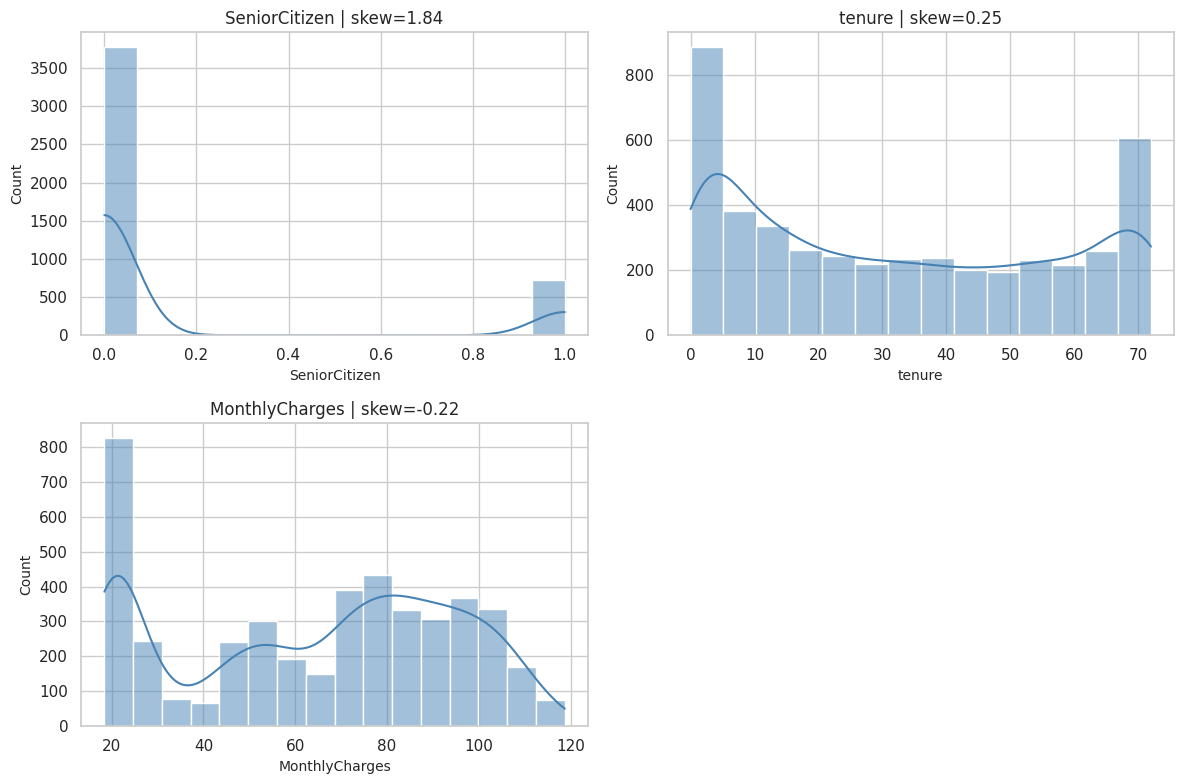

In [8]:
if not skew_report.empty:
    cols_to_plot = skew_report.head(min(8, len(skew_report)))["Feature"].tolist()
    n_cols = 2
    n_rows = int(np.ceil(len(cols_to_plot) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 4 * n_rows))
    axes = np.array(axes).reshape(-1)

    for ax, col in zip(axes, cols_to_plot):
        sns.histplot(X_train_raw[col], kde=True, color="steelblue", ax=ax)
        ax.set_title(f"{col} | skew={X_train_raw[col].skew():.2f}")

    for ax in axes[len(cols_to_plot):]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()

### 6.3. Cardinalidad de variables categóricas

In [9]:
cardinality_records = []
for col in categorical_columns_train:
    counts = X_train_raw[col].value_counts(dropna=False)
    n_unique = X_train_raw[col].nunique(dropna=True)
    cardinality_records.append({
        "Feature": col,
        "Unique_Values": n_unique,
        "Unique_Ratio_%": X_train_raw[col].nunique(dropna=True) / max(len(X_train_raw), 1) * 100,
        "Most_Frequent_%": counts.iloc[0] / max(len(X_train_raw), 1) * 100 if len(counts) else np.nan,
        "Suggested_Encoding": "Review high-cardinality encoding" if n_unique > HIGH_CARDINALITY_THRESHOLD else "One-Hot candidate"
    })

cardinality_report = pd.DataFrame(cardinality_records)
if not cardinality_report.empty:
    cardinality_report = cardinality_report.sort_values("Unique_Values", ascending=False)
    display(cardinality_report.head(TOP_DIAGNOSTIC_FEATURES))
else:
    print("No categorical features detected.")

,Feature,Unique_Values,Unique_Ratio_%,Most_Frequent_%,Suggested_Encoding
15,TotalCharges,4267,94.674950,0.177502,Review high-cardinality encoding
14,PaymentMethod,4,0.088751,33.503439,One-Hot candidate
7,OnlineBackup,3,0.066563,43.465720,One-Hot candidate
6,OnlineSecurity,3,0.066563,49.722654,One-Hot candidate
9,TechSupport,3,0.066563,49.412026,One-Hot candidate
8,DeviceProtection,3,0.066563,44.375416,One-Hot candidate
5,InternetService,3,0.066563,43.621034,One-Hot candidate
4,MultipleLines,3,0.066563,47.681385,One-Hot candidate
11,StreamingMovies,3,0.066563,39.605059,One-Hot candidate
10,StreamingTV,3,0.066563,39.294431,One-Hot candidate


### 6.4. Redundancia y correlación entre variables numéricas

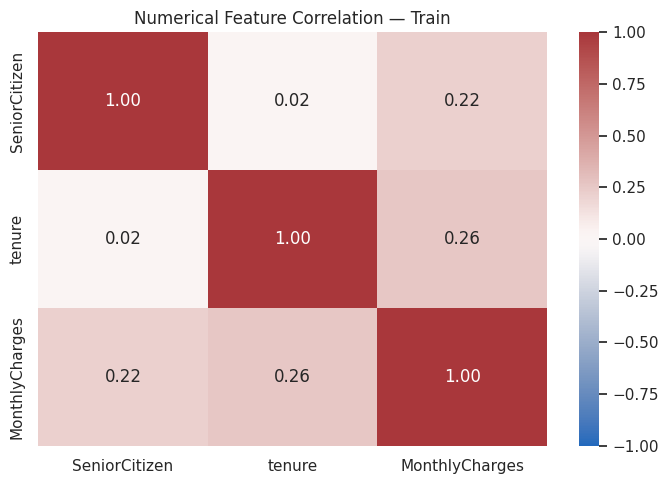

Pares con |correlación| >= 0.9:


,Feature_1,Feature_2,Correlation,Abs_Correlation


In [10]:
if len(numeric_columns_train) >= 2:
    numeric_corr = X_train_raw[numeric_columns_train].corr(method="pearson")

    plt.figure(figsize=(max(7, 0.65 * len(numeric_columns_train)), max(5, 0.55 * len(numeric_columns_train))))
    sns.heatmap(
        numeric_corr,
        cmap="vlag",
        center=0,
        vmin=-1,
        vmax=1,
        annot=len(numeric_columns_train) <= 12,
        fmt=".2f"
    )
    plt.title("Numerical Feature Correlation — Train")
    plt.tight_layout()
    plt.show()

    upper = numeric_corr.where(np.triu(np.ones(numeric_corr.shape), k=1).astype(bool))
    high_corr_pairs = (
        upper.stack()
        .rename("Correlation")
        .reset_index()
        .rename(columns={"level_0": "Feature_1", "level_1": "Feature_2"})
    )
    high_corr_pairs["Abs_Correlation"] = high_corr_pairs["Correlation"].abs()
    high_corr_pairs = high_corr_pairs[
        high_corr_pairs["Abs_Correlation"] >= HIGH_CORRELATION_THRESHOLD
    ].sort_values("Abs_Correlation", ascending=False)

    print(f"Pares con |correlación| >= {HIGH_CORRELATION_THRESHOLD}:")
    display(high_corr_pairs.head(TOP_DIAGNOSTIC_FEATURES) if not high_corr_pairs.empty else pd.DataFrame(columns=["Feature_1", "Feature_2", "Correlation", "Abs_Correlation"]))
else:
    print("Se necesitan al menos dos variables numéricas para analizar correlaciones.")

### 6.5. Checklist de oportunidades

Antes de activar una transformación, revisá:
- ¿La asimetría es real o corresponde a una variable con distribución naturalmente sesgada?
- ¿Una variable de alta cardinalidad es una categoría genuina o un identificador? Los identificadores suelen excluirse, no encodearse.
- ¿Dos variables muy correlacionadas representan información duplicada o conceptos distintos?
- ¿Una fecha representa el momento de observación, una fecha de alta o un evento futuro? Evitá usar información que no estaría disponible al momento de predecir.
- ¿Una interacción tiene sentido desde el dominio? Crear todas las combinaciones indiscriminadamente suele aumentar ruido y dimensionalidad.

## 7. Configuración de Feature Engineering

Activá únicamente las transformaciones que quieras experimentar. Las listas empiezan vacías para evitar aplicar operaciones que quizá no tengan sentido en el dataset.

**Transformaciones numéricas**
- `LOG1P_COLUMNS`: aplicar `log1p(x)`; requiere valores no negativos.
- `SIGNED_LOG_COLUMNS`: aplicar `sign(x) * log1p(abs(x))`; admite valores negativos.
- `SQUARE_COLUMNS`: agregar una columna al cuadrado, manteniendo también la original.

**Fechas**
- Se extraen componentes estándar de todas las columnas datetime detectadas en ambas variantes.
- `ADD_CYCLICAL_DATE_FEATURES` agrega codificación seno/coseno para mes y día de semana.
- `DATE_AGE_COLUMNS` calcula días transcurridos desde una fecha hasta `DATE_REFERENCE`.
- `DATE_DIFF_PAIRS` calcula `end_date - start_date` en días.

**Features derivadas**
- `NUMERIC_INTERACTIONS`: productos entre pares de variables numéricas.
- `RATIO_FEATURES`: cocientes `numerator / denominator`; los infinitos se convierten en nulos.
- `CATEGORICAL_INTERACTIONS`: combina dos categorías en una nueva categoría.
- `DROP_ENGINEERED_COLUMNS`: exclusiones manuales justificadas por redundancia/leakage.

Las columnas de alta cardinalidad se pueden tratar con One-Hot, frequency o target encoding. Target encoding solo se ajusta dentro del pipeline y utiliza cross-fitting para reducir leakage.

In [11]:
# Numeric transformations
LOG1P_COLUMNS = []                  # Ejemplo: ["income"] si todos los valores son >= 0
SIGNED_LOG_COLUMNS = []             # Ejemplo: ["balance"] si puede haber valores negativos
SQUARE_COLUMNS = []                 # Ejemplo: ["age"]

# Date features
DATE_COMPONENTS = ["year", "month", "day", "dayofweek", "quarter", "dayofyear"]
ADD_CYCLICAL_DATE_FEATURES = True
DATE_AGE_COLUMNS = []               # Ejemplo: ["signup_date"]
DATE_REFERENCE = None                # Ejemplo: "2026-01-01"; no usar fecha actual implícita
DATE_DIFF_PAIRS = []                 # Ejemplo: [("signup_date", "last_purchase_date")]

# Interactions and derived features
NUMERIC_INTERACTIONS = []            # Ejemplo: [("tenure", "MonthlyCharges")]
RATIO_FEATURES = []                  # Ejemplo: [("TotalCharges", "tenure")]
CATEGORICAL_INTERACTIONS = []         # Ejemplo: [("Contract", "PaymentMethod")]

# Drop only after reviewing redundancy or leakage
DROP_ENGINEERED_COLUMNS = []
DROP_REDUNDANT_COLUMNS = []          # Features que decidiste retirar por redundancia; se quitan de ambas variantes

print("Feature engineering configuration loaded.")

Feature engineering configuration loaded.


## 8. Funciones para crear features

In [12]:
def _require_columns(data, columns, context):
    missing = [col for col in columns if col not in data.columns]
    if missing:
        raise KeyError(f"Columnas inexistentes en {context}: {missing}")


def add_datetime_features(data, date_columns, include_advanced=False):
    """Expand datetime columns into standard calendar features."""
    result = data.copy()

    for col in date_columns:
        if col not in result.columns:
            continue
        dt = parse_datetime_series(result[col])

        component_map = {
            "year": dt.dt.year,
            "month": dt.dt.month,
            "day": dt.dt.day,
            "dayofweek": dt.dt.dayofweek,
            "quarter": dt.dt.quarter,
            "dayofyear": dt.dt.dayofyear,
            "hour": dt.dt.hour,
            "is_month_start": dt.dt.is_month_start.astype(float),
            "is_month_end": dt.dt.is_month_end.astype(float),
        }

        for component in DATE_COMPONENTS:
            if component not in component_map:
                raise ValueError(f"DATE_COMPONENTS contiene un componente no soportado: {component}")
            result[f"{col}__{component}"] = component_map[component]

        if include_advanced and ADD_CYCLICAL_DATE_FEATURES:
            result[f"{col}__month_sin"] = np.sin(2 * np.pi * (dt.dt.month - 1) / 12)
            result[f"{col}__month_cos"] = np.cos(2 * np.pi * (dt.dt.month - 1) / 12)
            result[f"{col}__weekday_sin"] = np.sin(2 * np.pi * dt.dt.dayofweek / 7)
            result[f"{col}__weekday_cos"] = np.cos(2 * np.pi * dt.dt.dayofweek / 7)

        if include_advanced and col in DATE_AGE_COLUMNS:
            if DATE_REFERENCE is None:
                raise ValueError("Definí DATE_REFERENCE para utilizar DATE_AGE_COLUMNS.")
            reference = pd.Timestamp(DATE_REFERENCE)
            result[f"{col}__age_days"] = (reference - dt).dt.total_seconds() / 86400

        result = result.drop(columns=col)

    if include_advanced and DATE_DIFF_PAIRS:
        for start_col, end_col in DATE_DIFF_PAIRS:
            _require_columns(data, [start_col, end_col], "DATE_DIFF_PAIRS")
            start = parse_datetime_series(data[start_col])
            end = parse_datetime_series(data[end_col])
            result[f"days_between__{start_col}__{end_col}"] = (end - start).dt.total_seconds() / 86400
            # Drop raw date columns if they were detected and not already expanded.
            for col in [start_col, end_col]:
                if col in result.columns and col in date_columns:
                    result = result.drop(columns=col)

    return result


def add_derived_features(data):
    """Add user-configured numeric and categorical derived features."""
    result = data.copy()

    for col in LOG1P_COLUMNS:
        _require_columns(result, [col], "LOG1P_COLUMNS")
        values = pd.to_numeric(result[col], errors="coerce")
        if (values.dropna() < 0).any():
            raise ValueError(f"{col}: log1p requiere valores no negativos. Usá SIGNED_LOG_COLUMNS si corresponde.")
        result[f"{col}__log1p"] = np.log1p(values)

    for col in SIGNED_LOG_COLUMNS:
        _require_columns(result, [col], "SIGNED_LOG_COLUMNS")
        values = pd.to_numeric(result[col], errors="coerce")
        result[f"{col}__signed_log"] = np.sign(values) * np.log1p(np.abs(values))

    for col in SQUARE_COLUMNS:
        _require_columns(result, [col], "SQUARE_COLUMNS")
        values = pd.to_numeric(result[col], errors="coerce")
        result[f"{col}__squared"] = values ** 2

    for col_a, col_b in NUMERIC_INTERACTIONS:
        _require_columns(result, [col_a, col_b], "NUMERIC_INTERACTIONS")
        a = pd.to_numeric(result[col_a], errors="coerce")
        b = pd.to_numeric(result[col_b], errors="coerce")
        result[f"{col_a}__x__{col_b}"] = a * b

    for numerator, denominator in RATIO_FEATURES:
        _require_columns(result, [numerator, denominator], "RATIO_FEATURES")
        num = pd.to_numeric(result[numerator], errors="coerce")
        den = pd.to_numeric(result[denominator], errors="coerce").replace(0, np.nan)
        ratio = num / den
        result[f"{numerator}__per__{denominator}"] = ratio.replace([np.inf, -np.inf], np.nan)

    for col_a, col_b in CATEGORICAL_INTERACTIONS:
        _require_columns(result, [col_a, col_b], "CATEGORICAL_INTERACTIONS")
        a = result[col_a].astype("string").fillna("__MISSING__")
        b = result[col_b].astype("string").fillna("__MISSING__")
        result[f"{col_a}__x__{col_b}__cat"] = a + "__" + b

    if DROP_ENGINEERED_COLUMNS:
        existing = [col for col in DROP_ENGINEERED_COLUMNS if col in result.columns]
        result = result.drop(columns=existing)

    return result


def add_custom_features(data):
    """Edit this function to add domain-specific features."""
    result = data.copy()

    # Example:
    # if {"TotalCharges", "tenure"}.issubset(result.columns):
    #     result["avg_monthly_charge"] = result["TotalCharges"] / result["tenure"].replace(0, np.nan)

    return result


def normalize_categorical_dtypes(data):
    """Normalize categorical values to strings and keep missing values as np.nan."""
    result = data.copy()
    for col in get_categorical_columns(result):
        result[col] = result[col].astype("string").astype(object)
        result[col] = result[col].where(pd.notna(result[col]), np.nan)
    return result


def build_feature_variants(data, date_columns):
    """Return baseline and engineered feature DataFrames."""
    configured_date_columns = list(date_columns)
    configured_date_columns += list(DATE_AGE_COLUMNS)
    configured_date_columns += [col for pair in DATE_DIFF_PAIRS for col in pair]
    configured_date_columns = list(dict.fromkeys(configured_date_columns))

    baseline = add_datetime_features(
        data,
        date_columns=configured_date_columns,
        include_advanced=False
    )

    engineered = add_datetime_features(
        data,
        date_columns=configured_date_columns,
        include_advanced=True
    )
    engineered = add_derived_features(engineered)
    engineered = add_custom_features(engineered)

    if DROP_REDUNDANT_COLUMNS:
        baseline = baseline.drop(columns=[c for c in DROP_REDUNDANT_COLUMNS if c in baseline.columns])
        engineered = engineered.drop(columns=[c for c in DROP_REDUNDANT_COLUMNS if c in engineered.columns])

    # Ensure bools and mixed-type categories are safely handled by imputers/encoders.
    baseline = normalize_categorical_dtypes(baseline)
    engineered = normalize_categorical_dtypes(engineered)

    return baseline, engineered

## 9. Crear las dos variantes de features

Se aplican las mismas operaciones fila a fila a train, validation y test. Las transformaciones configuradas son deterministas; los parámetros aprendidos (imputación, frecuencia de categorías y target encoding) se ajustarán después dentro de los pipelines usando solamente el segmento de entrenamiento correspondiente.

In [13]:
X_train_base, X_train_engineered = build_feature_variants(X_train_raw, detected_datetime_columns)
X_valid_base, X_valid_engineered = build_feature_variants(X_valid_raw, detected_datetime_columns)
X_test_base, X_test_engineered = build_feature_variants(X_test_raw, detected_datetime_columns)

# Keep column order consistent across partitions.
for name, train_frame, valid_frame, test_frame in [
    ("baseline", X_train_base, X_valid_base, X_test_base),
    ("engineered", X_train_engineered, X_valid_engineered, X_test_engineered)
]:
    missing_valid = set(train_frame.columns) - set(valid_frame.columns)
    missing_test = set(train_frame.columns) - set(test_frame.columns)
    extra_valid = set(valid_frame.columns) - set(train_frame.columns)
    extra_test = set(test_frame.columns) - set(train_frame.columns)
    if missing_valid or missing_test or extra_valid or extra_test:
        raise ValueError(f"Las columnas de {name} no coinciden entre train/validation/test.")

print("Baseline features:", X_train_base.shape)
print("Engineered features:", X_train_engineered.shape)
print("Nuevas features:", sorted(set(X_train_engineered.columns) - set(X_train_base.columns)))

Baseline features: (4507, 19)
Engineered features: (4507, 19)
Nuevas features: []


## 10. Encoding y preprocessing

La notebook combina:
- Imputación numérica con mediana.
- Escalado numérico opcional.
- One-Hot Encoding para categorías de cardinalidad baja o media.
- Encoding configurable para alta cardinalidad: frequency, target u One-Hot limitado.

El corte de alta cardinalidad se calcula mirando `X_train` de cada variante. Los encoders se ajustan dentro del Pipeline, evitando aprender estadísticas de validation/test.

In [14]:
class FrequencyEncoder(BaseEstimator, TransformerMixin):
    """Encode each categorical column using its training frequency."""

    def fit(self, X, y=None):
        X_frame = pd.DataFrame(X).copy()
        self.feature_names_in_ = np.asarray(
            getattr(X, "columns", [f"x{i}" for i in range(X_frame.shape[1])]),
            dtype=object
        )
        self.frequency_maps_ = []
        for col in X_frame.columns:
            values = X_frame[col].map(
                lambda value: "__MISSING__" if pd.isna(value) else str(value)
            )
            self.frequency_maps_.append(values.value_counts(normalize=True).to_dict())
        return self

    def transform(self, X):
        X_frame = pd.DataFrame(X).copy()
        encoded = np.zeros((len(X_frame), X_frame.shape[1]), dtype=float)
        for idx, col in enumerate(X_frame.columns):
            values = X_frame[col].map(
                lambda value: "__MISSING__" if pd.isna(value) else str(value)
            )
            encoded[:, idx] = values.map(self.frequency_maps_[idx]).fillna(0.0).to_numpy()
        return encoded

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features if input_features is not None else self.feature_names_in_, dtype=object)


def make_one_hot_encoder(max_categories=None):
    kwargs = {"handle_unknown": "ignore"}
    if max_categories is not None:
        kwargs["max_categories"] = max_categories
    if OHE_MIN_FREQUENCY is not None:
        kwargs["min_frequency"] = OHE_MIN_FREQUENCY
    try:
        return OneHotEncoder(sparse_output=True, **kwargs)
    except TypeError:  # scikit-learn < 1.2
        return OneHotEncoder(sparse=True, **kwargs)


def make_preprocessor(X_fit):
    numeric_cols = get_numeric_columns(X_fit)
    categorical_cols = get_categorical_columns(X_fit)

    high_card_cols = [
        col for col in categorical_cols
        if X_fit[col].nunique(dropna=True) > HIGH_CARDINALITY_THRESHOLD
    ]
    low_card_cols = [col for col in categorical_cols if col not in high_card_cols]

    transformers = []

    if numeric_cols:
        numeric_steps = [("imputer", SimpleImputer(strategy="median", keep_empty_features=True))]
        if SCALE_NUMERIC:
            numeric_steps.append(("scaler", StandardScaler()))
        transformers.append(("numeric", Pipeline(numeric_steps), numeric_cols))

    if low_card_cols:
        low_cat_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="__MISSING__")),
            ("onehot", make_one_hot_encoder(max_categories=OHE_MAX_CATEGORIES))
        ])
        transformers.append(("categorical_low", low_cat_pipe, low_card_cols))

    if high_card_cols:
        encoding = HIGH_CARDINALITY_ENCODING.lower()
        if encoding == "frequency":
            high_cat_pipe = Pipeline([
                ("frequency", FrequencyEncoder())
            ])
        elif encoding == "target" and TARGET_ENCODER_AVAILABLE:
            high_cat_pipe = Pipeline([
                ("imputer", SimpleImputer(strategy="constant", fill_value="__MISSING__")),
                ("target", TargetEncoder(target_type="auto", smooth="auto", cv=5))
            ])
        elif encoding == "onehot":
            high_cat_pipe = Pipeline([
                ("imputer", SimpleImputer(strategy="constant", fill_value="__MISSING__")),
                ("onehot", make_one_hot_encoder(max_categories=OHE_MAX_CATEGORIES))
            ])
        elif encoding == "target" and not TARGET_ENCODER_AVAILABLE:
            print("TargetEncoder no disponible: fallback a frequency encoding.")
            high_cat_pipe = Pipeline([("frequency", FrequencyEncoder())])
        else:
            raise ValueError("HIGH_CARDINALITY_ENCODING debe ser 'frequency', 'target' o 'onehot'.")
        transformers.append(("categorical_high", high_cat_pipe, high_card_cols))

    if not transformers:
        raise ValueError("No se detectaron variables numéricas ni categóricas para preprocessing.")

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        verbose_feature_names_out=False
    )

    summary = {
        "numeric": numeric_cols,
        "categorical_low_cardinality": low_card_cols,
        "categorical_high_cardinality": high_card_cols
    }
    return preprocessor, summary


def make_model():
    if MODEL_NAME.lower() == "random_forest":
        if problem_type == "classification":
            return RandomForestClassifier(
                n_estimators=N_ESTIMATORS,
                max_depth=MAX_DEPTH,
                random_state=RANDOM_STATE,
                n_jobs=MODEL_N_JOBS,
                class_weight="balanced_subsample"
            )
        return RandomForestRegressor(
            n_estimators=N_ESTIMATORS,
            max_depth=MAX_DEPTH,
            random_state=RANDOM_STATE,
            n_jobs=MODEL_N_JOBS
        )

    if MODEL_NAME.lower() == "xgboost":
        if not XGBOOST_AVAILABLE:
            raise ImportError("Instalá xgboost o seleccioná MODEL_NAME='random_forest'.")
        if problem_type == "classification":
            n_classes = pd.Series(y_train).nunique()
            objective = "binary:logistic" if n_classes == 2 else "multi:softprob"
            kwargs = {"objective": objective, "n_estimators": N_ESTIMATORS,
                      "max_depth": 6 if MAX_DEPTH is None else MAX_DEPTH,
                      "learning_rate": 0.05, "subsample": 0.9,
                      "colsample_bytree": 0.9, "random_state": RANDOM_STATE,
                      "n_jobs": MODEL_N_JOBS, "eval_metric": "logloss" if n_classes == 2 else "mlogloss"}
            if n_classes > 2:
                kwargs["num_class"] = n_classes
            return XGBClassifier(**kwargs)
        return XGBRegressor(
            objective="reg:squarederror",
            n_estimators=N_ESTIMATORS,
            max_depth=6 if MAX_DEPTH is None else MAX_DEPTH,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=RANDOM_STATE,
            n_jobs=MODEL_N_JOBS
        )

    raise ValueError("MODEL_NAME debe ser 'random_forest' o 'xgboost'.")

print("Preprocessing y model factory listos.")

Preprocessing y model factory listos.


## 11. Comparación de baseline vs. engineered features

In [15]:
def build_model_pipeline(X_fit):
    preprocessor, preprocessing_summary = make_preprocessor(X_fit)
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", make_model())
    ])
    return pipeline, preprocessing_summary


def calculate_metrics(model, X_eval, y_eval):
    predictions = model.predict(X_eval)
    metrics = {}

    if problem_type == "classification":
        metrics["accuracy"] = accuracy_score(y_eval, predictions)
        metrics["precision_weighted"] = precision_score(y_eval, predictions, average="weighted", zero_division=0)
        metrics["recall_weighted"] = recall_score(y_eval, predictions, average="weighted", zero_division=0)
        metrics["f1_weighted"] = f1_score(y_eval, predictions, average="weighted", zero_division=0)

        if hasattr(model, "predict_proba"):
            probabilities = model.predict_proba(X_eval)
            n_classes = len(np.unique(y_eval))
            try:
                if n_classes == 2:
                    metrics["roc_auc"] = roc_auc_score(y_eval, probabilities[:, 1])
                    metrics["pr_auc"] = average_precision_score(y_eval, probabilities[:, 1])
                else:
                    metrics["roc_auc"] = roc_auc_score(y_eval, probabilities, multi_class="ovr", average="weighted")
            except ValueError:
                metrics["roc_auc"] = np.nan
    else:
        y_true = np.asarray(y_eval, dtype=float)
        y_pred = np.asarray(predictions, dtype=float)
        metrics["mae"] = mean_absolute_error(y_true, y_pred)
        metrics["rmse"] = np.sqrt(mean_squared_error(y_true, y_pred))
        metrics["r2"] = r2_score(y_true, y_pred) if len(y_true) > 1 else np.nan
        if np.all(y_true >= 0):
            y_pred_nonnegative = np.clip(y_pred, 0, None)
            metrics["logrmse"] = np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(y_pred_nonnegative)))
        else:
            metrics["logrmse"] = np.nan

    return metrics


variants = {
    "baseline": (X_train_base, X_valid_base),
    "engineered": (X_train_engineered, X_valid_engineered)
}

fitted_pipelines = {}
preprocessing_summaries = {}
validation_records = []

for variant_name, (X_fit, X_eval) in variants.items():
    print(f"\nTraining variant: {variant_name}")
    pipeline, prep_summary = build_model_pipeline(X_fit)
    pipeline.fit(X_fit, y_train)
    fitted_pipelines[variant_name] = pipeline
    preprocessing_summaries[variant_name] = prep_summary

    metrics = calculate_metrics(pipeline, X_eval, y_valid)
    validation_records.append({"Variant": variant_name, **metrics})
    print("Preprocessing:", prep_summary)

validation_results = pd.DataFrame(validation_records).set_index("Variant")
print("\nValidation results:")
display(validation_results.round(4))


Training variant: baseline
Preprocessing: {'numeric': ['SeniorCitizen', 'tenure', 'MonthlyCharges'], 'categorical_low_cardinality': ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod'], 'categorical_high_cardinality': ['TotalCharges']}

Training variant: engineered
Preprocessing: {'numeric': ['SeniorCitizen', 'tenure', 'MonthlyCharges'], 'categorical_low_cardinality': ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod'], 'categorical_high_cardinality': ['TotalCharges']}

Validation results:


,accuracy,precision_weighted,recall_weighted,f1_weighted,roc_auc,pr_auc
Variant,,,,,,
baseline,0.7835,0.7696,0.7835,0.7718,0.817,0.6009
engineered,0.7835,0.7696,0.7835,0.7718,0.817,0.6009


## 12. Selección de variante y comparación visual

In [ ]:
selection_metric = (
    SELECTION_METRIC_CLASSIFICATION
    if problem_type == "classification"
    else SELECTION_METRIC_REGRESSION
)

if selection_metric not in validation_results.columns:
    raise ValueError(
        f"La métrica de selección '{selection_metric}' no está disponible. "
        f"Métricas calculadas: {validation_results.columns.tolist()}"
    )

ascending = problem_type == "regression"  # RMSE/MAE/LogRMSE: menor es mejor
valid_scores = validation_results[selection_metric].dropna()
if valid_scores.empty:
    raise ValueError(f"No hay valores válidos para seleccionar por {selection_metric}.")

best_variant = valid_scores.sort_values(ascending=ascending).index[0]
print(f"Métrica de selección: {selection_metric}")
print(f"Variante seleccionada en validation: {best_variant}")

plt.figure(figsize=(7, 4))
sns.barplot(
    x=validation_results.index,
    y=validation_results[selection_metric],
    color="steelblue"
)
plt.title(f"Baseline vs Engineered — Validation ({selection_metric})")
plt.xlabel("Feature set")
plt.ylabel(selection_metric)
plt.tight_layout()
plt.show()

## 13. Evaluación final en test

Se reentrena la variante elegida utilizando train + validation y se evalúa una sola vez sobre test. No se comparan múltiples variantes en test para evitar convertirlo en otro conjunto de validación.

In [ ]:
if best_variant == "baseline":
    X_trainval = pd.concat([X_train_base, X_valid_base], axis=0)
    X_test_selected = X_test_base
else:
    X_trainval = pd.concat([X_train_engineered, X_valid_engineered], axis=0)
    X_test_selected = X_test_engineered

y_trainval = pd.concat([y_train, y_valid], axis=0)

final_pipeline, final_preprocessing_summary = build_model_pipeline(X_trainval)
final_pipeline.fit(X_trainval, y_trainval)

test_metrics = calculate_metrics(final_pipeline, X_test_selected, y_test)
print(f"Final test metrics — {best_variant} features")
display(pd.DataFrame([test_metrics], index=[best_variant]).round(4))

## 14. Revisar las nuevas features

In [ ]:
base_columns = set(X_train_base.columns)
engineered_columns = set(X_train_engineered.columns)
new_features = sorted(engineered_columns - base_columns)

new_feature_summary = pd.DataFrame({
    "Feature": new_features,
    "Dtype": [str(X_train_engineered[col].dtype) for col in new_features],
    "Missing_%": [X_train_engineered[col].isna().mean() * 100 for col in new_features],
    "Unique_Values": [X_train_engineered[col].nunique(dropna=True) for col in new_features]
})

display(new_feature_summary)

if new_features:
    print("Distribuciones de nuevas features numéricas:")
    new_numeric = [col for col in new_features if col in get_numeric_columns(X_train_engineered)]
    if new_numeric:
        display(X_train_engineered[new_numeric].describe().T)

## 15. Exportación opcional de las features engineered

Esta exportación guarda la matriz **antes de imputación, escalado y encoding**. No es un dataset listo para entrenar por sí solo: conserva categóricas y nulos, para que el preprocessing siga aprendiendo dentro de los pipelines.

In [ ]:
if SAVE_ENGINEERED_DATA:
    export_df = X_train_engineered.copy()
    export_df[TARGET] = y_train
    export_df.to_csv(ENGINEERED_DATA_PATH, index=True)
    print(f"Features engineered de train exportadas en: {ENGINEERED_DATA_PATH.resolve()}")
else:
    print("Exportación desactivada. Cambiá SAVE_ENGINEERED_DATA=True para guardar train engineered.")

## 16. Conclusiones y próximos pasos

Al finalizar, registrá:
1. Qué diagnósticos motivaron las transformaciones.
2. Qué features nuevas se probaron y por qué tienen sentido para el dominio.
3. Qué encoding se utilizó para variables de alta cardinalidad.
4. Si la variante engineered mejoró validation respecto de baseline.
5. Si la mejora se mantuvo en el test reservado.

**No conserves una transformación solamente porque aumentó una métrica una vez.** Revisá estabilidad con cross-validation, importancia/SHAP, sensibilidad a la partición y plausibilidad del dominio. Si vas a iterar muchas veces, incorporá cross-validation dentro de train y mantené validation como criterio de selección.

### Checklist antes de pasar a Model Optimization
- [ ] No hay features que usen información posterior al momento de predicción.
- [ ] No hay IDs o columnas que filtren indirectamente el target.
- [ ] Las transformaciones tienen sentido para el dominio.
- [ ] No se ajustaron imputadores/encoders con validation o test.
- [ ] Se compararon baseline y engineered con la misma partición y modelo.
- [ ] Se dejó test reservado hasta elegir la variante.